### System identification

The parameters of the simulation that predict a recorded run of the robot best, see README §12.4. `RUN` is a `.jsonl` saved by `twin.py` or a `--log` csv of `ball_balancer.py`, or a run the dashboard recorded in `scripts/runs/`.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt

from system_id import load, replay, cost, fit, by_age

RUN = "../scripts/runs/run_20261026_165651.jsonl"   # the 72 s PID run of this build, README §16.4
HORIZON = 0.5                                     # [s] between two resyncs of the simulated ball
KEYS = ("latency", "servo_tau", "deadband", "px_per_m", "rolling", "bias_x", "bias_y")

### Run

In [2]:
msgs = load(RUN)
t = np.array([m["t"] for m in msgs])
print(f"{len(msgs)} frames over {t[-1] - t[0]:.1f} s, {sum(m['ball'] is not None for m in msgs)} with the ball")

4658 frames over 167.8 s, 2573 with the ball


### Fit

Nelder-Mead from the nominal parameters, about ten minutes on a run of this length.

In [3]:
params, after, before = fit(msgs, KEYS, HORIZON, maxiter=300)
print(f"mean drift within {HORIZON} s of a resync: nominal {before:.1f} px, fitted {after:.1f} px")
for k, v in params.items():
    print(f"  {k:10s} {v:.4g}")
with open("twin_logs/fitted.json", "w") as f:
    json.dump(params, f, indent=1)      # mjpython twin.py --params twin_logs/fitted.json

mean drift within 0.5 s of a resync: nominal 53.3 px, fitted 10.1 px
  latency    0.01591
  servo_tau  0.06119
  deadband   1.831
  px_per_m   2327
  rolling    0.0004837
  bias_x     -0.002256
  bias_y     -0.05288


### Drift after a resync

The ball is unstable, so the simulated ball drifts from the measured one whatever the parameters; the better the simulation, the slower.

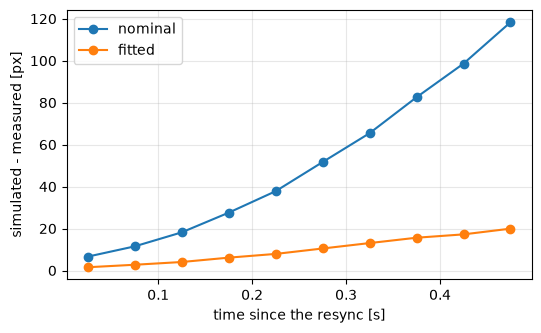

In [4]:
edges = np.arange(0, HORIZON + 1e-9, 0.05)
rows_nominal = replay(msgs, None, HORIZON)
rows_fitted = replay(msgs, params, HORIZON)
mid = (edges[:-1] + edges[1:]) / 2
plt.figure(figsize=(6, 3.5))
plt.plot(mid, by_age(rows_nominal, edges), "o-", label="nominal")
plt.plot(mid, by_age(rows_fitted, edges), "o-", label="fitted")
plt.xlabel("time since the resync [s]")
plt.ylabel("simulated - measured [px]")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Measured and simulated ball

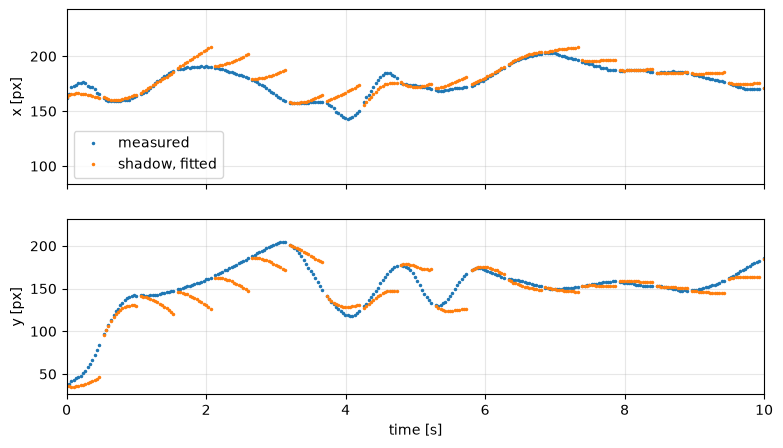

In [5]:
t0 = rows_fitted[0]["t"]
fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
for ax, i, name in zip(axes, (0, 1), ("x", "y")):
    ax.plot([r["t"] - t0 for r in rows_fitted], [r["meas"][i] for r in rows_fitted], ".", ms=3, label="measured")
    ax.plot([r["t"] - t0 for r in rows_fitted], [r["sim"][i] for r in rows_fitted], ".", ms=3, label="shadow, fitted")
    ax.set_ylabel(f"{name} [px]")
    ax.grid(alpha=0.3)
axes[0].legend()
axes[1].set_xlabel("time [s]")
axes[1].set_xlim(0, 10)
plt.show()